# Predicting the final size of a wildfire at discovery

**Milestone 2.** Sections 1 to 5 take up milestone 1, with two changes following the lecturers' feedback: the data now cover three years (2018, 2019, 2020), one per set (train, validation, test), and the training set is no longer subsampled. Sections 6 to 12 are new.

## 1. Data

* **FPA FOD-Attributes**, https://zenodo.org/records/8381129 (description: https://essd.copernicus.org/articles/16/3045/2024/). More than 2.3 million US wildfire ignitions (1992 to 2020) described by nearly 270 physical, biological, social and administrative attributes, in one CSV file per year.
* **How and why:** FPA FOD (USDA Forest Service) gathers the wildfire reports of federal, state and local agencies into one national database, used for fire management planning and research. Pourmohamad et al. (2024) added the attributes by extracting, at the place and date of each ignition, values from 24 sources (weather, vegetation, terrain, population, firefighting resources).
* **Application domain:** wildfire risk and emergency management, close to the Copernicus Emergency Management Service (EFFIS in Europe).
* **Scope:** years 2018, 2019 and 2020 (one CSV file each, downloaded from Zenodo and reduced to the 37 columns we use by the first code cell), all states of USA except Alaska, Hawaii and Puerto Rico.

In [1]:
import os
import urllib.request

# Downloads the Zenodo files if missing and keeps only the columns we use ({year}_FPA_FOD_light.csv). Nothing is done if the light files exist.
ZENODO = "https://zenodo.org/records/8381129/files/{}?download=1"

COLS = [
    "STATE", "FIRE_SIZE", "DISCOVERY_DATE", "DISCOVERY_DOY", "DISCOVERY_TIME",  # target and time
    "LATITUDE", "LONGITUDE", "pr", "tmmx", "rmin", "vs", "vpd", "erc", "bi", "fm100", "fm1000",
    "Aridity_index", "MOD_NDVI_12m", "Land_Cover_1km", "FRG_1km", "Elevation", "Slope", "TRI",
    "Popo_1km", "GHM", "No_FireStation_10.0km", "SDI", "NPL", "GACC_PL", "RPL_THEMES", "GAP_Sts",
    "road_county_dis", "road_interstate_dis", "road_common_name_dis",
    "road_other_dis", "road_state_dis", "road_US_dis",
]


def prepare(years=(2018, 2019, 2020)):
    for year in years:
        raw, light = f"{year}_FPA_FOD_cons.csv", f"{year}_FPA_FOD_light.csv"
        if os.path.exists(light):
            continue
        if not os.path.exists(raw):
            print(f"Downloading {raw} from Zenodo...")
            urllib.request.urlretrieve(ZENODO.format(raw), raw)
        pd.read_csv(raw, usecols=COLS, low_memory=False)[COLS].to_csv(light, index=False)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prepare()

df = pd.concat([pd.read_csv(f"{year}_FPA_FOD_light.csv", low_memory=False) for year in (2018, 2019, 2020)], ignore_index=True)
df = df[~df["STATE"].isin(["AK", "HI", "PR"])].reset_index(drop=True)
df.shape

(215098, 37)

## 2. Learning task

* **Question:** when a fire is discovered, what will its final size be?
* **Task:** supervised multi-class classification with 5 ordered classes. One observation = one fire.
* **Output `y`:** class of the final burned area `FIRE_SIZE`, built from the official classes A to G:

| `y` | Class | Official classes | Final size |
|---|---|---|---|
| 0 | very small | A | less than 0.26 acres (0.1 ha) |
| 1 | small | B | 0.26 to 9.9 acres (0.1 to 4 ha) |
| 2 | medium | C | 10 to 99.9 acres (4 to 40 ha) |
| 3 | medium-large | D | 100 to 299 acres (40 to 121 ha) |
| 4 | large | E, F, G | 300 acres or more (121 ha or more) |

**Why these classes:**
* They are the official size classes of the NWCG (*National Wildfire Coordinating Group*), used by US firefighting agencies and already present in FPA FOD (`FIRE_SIZE_CLASS`).
* Classes E, F and G are merged because they are too rare on their own.
* Predicting a class rather than the exact area is more robust: `FIRE_SIZE` ranges from 0.0007 to 589,368 acres.

In [3]:
CLASSES = ["very small (A)", "small (B)", "medium (C)", "medium-large (D)", "large (E-G)"]

y = pd.cut(df["FIRE_SIZE"], bins=[0, 0.26, 10, 100, 300, np.inf], right=False, labels=False).rename("size_class")
y.value_counts().sort_index().rename(index=dict(enumerate(CLASSES)))

size_class
very small (A)      105248
small (B)            86917
medium (C)           17315
medium-large (D)      2751
large (E-G)           2867
Name: count, dtype: int64

The classes are highly imbalanced: very small and small fires make up 89% of all fires, against 8% for medium, 1.3% for medium-large and 1.3% for large fires.

## 3. Explanatory variables

We keep only variables **known at the time of discovery** (30 in total):

| Theme | Variables | Meaning | Type |
|---|---|---|---|
| Location | `LATITUDE`, `LONGITUDE` | coordinates of the ignition point (°) | numerical |
| Time | `DOY_SIN`, `DOY_COS`, `DISCOVERY_HOUR` | day of year with cyclical encoding: sine and cosine of 2π × day / 366. 31 December is thus close to 1 January. Hour of discovery (0 to 23) | numerical, derived |
| Daily weather | `pr`, `tmmx`, `rmin`, `vs`, `vpd` | precipitation (mm), maximum temperature (K), minimum relative humidity (%), wind speed (m/s), vapour pressure deficit (kPa) | numerical |
| Fire danger | `erc`, `bi`, `fm100`, `fm1000` | fire danger indices (energy release, burning intensity), dead fuel moisture (%) | numerical |
| Climate | `Aridity_index` | annual precipitation divided by potential evapotranspiration (low = arid) | numerical |
| Vegetation | `MOD_NDVI_12m_mean` | mean MODIS NDVI over the 12 months before the fire (-1 to 1) | numerical, derived |
| Land cover | `Land_Cover_1km_main` | most frequent NLCD class within 1 km | **categorical** (15 classes), derived |
| Fire regime | `FRG_1km_main` | most frequent LANDFIRE fire regime group within 1 km | **categorical** (10 classes), derived |
| Terrain | `Elevation`, `Slope`, `TRI` | elevation (m), slope (°), terrain ruggedness | numerical |
| Human presence | `Popo_1km`, `GHM`, `Distance_to_road` | mean population density within 1 km, global human modification index (0 to 1), minimum of the six road distance columns | numerical |
| Firefighting | `No_FireStation_10.0km`, `SDI`, `NPL`, `GACC_PL` | fire stations within 10 km, suppression difficulty (static map computed before the fire), national and regional preparedness levels on the discovery day (1 to 5) | numerical, ordinal |
| Social, land management | `RPL_THEMES`, `GAP_Sts` | overall social vulnerability (0 to 1), protection status of the land (1 to 4) | numerical, ordinal |

The derived variables are computed from columns of the dataset. `MOD_NDVI_12m` stores the 12 monthly values in a single text cell. `Land_Cover_1km` and `FRG_1km` store the most frequent classes with their share (for example `52(58%) / 82(17%) / 71(13%)`): we keep the first, most frequent code. `DISCOVERY_HOUR` is the hhmm discovery time divided by 100 (1430 gives 14). `Distance_to_road` is the minimum of the six `road_*_dis` columns, ignoring missing values.

**Columns excluded because they reveal the answer or are only known after the fire:** `FIRE_SIZE_CLASS` (almost the target itself), `CONT_DATE` and `CONT_TIME` (containment), the cause, `MTBS_ID` and the ICS-209 identifiers (exist only for large fires), the 5-day weather windows (include the 2 days after ignition).

In [4]:
NUM_FEATURES = ["LATITUDE", "LONGITUDE", "DOY_SIN", "DOY_COS", "DISCOVERY_HOUR",
                "pr", "tmmx", "rmin", "vs", "vpd",
                "erc", "bi", "fm100", "fm1000",
                "Aridity_index", "MOD_NDVI_12m_mean",
                "Elevation", "Slope", "TRI",
                "Popo_1km", "GHM", "Distance_to_road",
                "No_FireStation_10.0km", "SDI", "NPL", "GACC_PL",
                "RPL_THEMES", "GAP_Sts"]
CAT_FEATURES = ["Land_Cover_1km_main", "FRG_1km_main"]

ROADS = ["road_county_dis", "road_interstate_dis", "road_common_name_dis",
         "road_other_dis", "road_state_dis", "road_US_dis"]

# Derived variables, computed from existing columns
derived = pd.DataFrame({
    "DOY_SIN": np.sin(2 * np.pi * df["DISCOVERY_DOY"] / 366),
    "DOY_COS": np.cos(2 * np.pi * df["DISCOVERY_DOY"] / 366),
    "DISCOVERY_HOUR": df["DISCOVERY_TIME"] // 100,
    "MOD_NDVI_12m_mean": df["MOD_NDVI_12m"].str.replace("'", "").str.split(expand=True).astype(float).mean(axis=1),
    "Distance_to_road": df[ROADS].min(axis=1),
    "Land_Cover_1km_main": df["Land_Cover_1km"].str.split("(").str[0],
    "FRG_1km_main": df["FRG_1km"].str.split("(").str[0],
})

print("Number of features:", len(NUM_FEATURES) + len(CAT_FEATURES))

X = df.join(derived)[NUM_FEATURES + CAT_FEATURES].copy()

Number of features: 30


## 4. Descriptive analysis

### Preliminary cleaning

* Some columns encode missing data with an extreme value (-3.4e36 for `SDI`, -3.4e38 for `GHM`, -999 for `RPL_THEMES`). These values are replaced with missing values.
* `No_FireStation_10.0km` is empty when there is no fire station within the radius: we replace it with 0.
* In `FRG_1km_main`, the code -9999 (39 fires) means "no data". It is kept as a separate category.
* `DISCOVERY_HOUR` and `Distance_to_road` are often empty. They are imputed in section 5.

The table below gives the main statistics of the numerical variables and their share of missing values.

In [5]:
X[NUM_FEATURES] = X[NUM_FEATURES].mask(X[NUM_FEATURES] <= -999)
X["No_FireStation_10.0km"] = X["No_FireStation_10.0km"].fillna(0)

stats = X[NUM_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
stats["missing_%"] = X[NUM_FEATURES].isna().mean() * 100
stats.round(2)

,mean,std,min,50%,max,missing_%
LATITUDE,37.97,5.15,24.67,37.58,49.00,0.00
LONGITUDE,-99.00,15.37,-124.71,-98.21,-66.99,0.00
DOY_SIN,0.11,0.72,-1.00,0.15,1.00,0.00
DOY_COS,-0.27,0.64,-1.00,-0.42,1.00,0.00
DISCOVERY_HOUR,14.11,4.62,0.00,14.00,23.00,20.53
pr,1.21,4.75,0.00,0.00,164.30,0.00
tmmx,297.94,8.97,252.50,298.80,322.70,0.00
rmin,28.63,13.98,1.00,27.40,100.00,0.00
vs,3.90,1.67,0.30,3.60,19.20,0.00
vpd,1.39,0.93,0.00,1.14,7.11,0.00


The table above shows that most variables have no missing values. The exceptions are `DISCOVERY_HOUR` (21%) and `Distance_to_road` (31%), imputed in section 5. The scales are very different (temperatures around 298 K, elevation up to 3,825 m, NDVI between -0.3 and 0.9), so standardisation is planned in section 5. Several variables are highly skewed: daily precipitation is zero for more than half of the fires (median 0, maximum 164 mm), and population density within 1 km has a median of 0.17 for a maximum of 310.

### Figure 1: where each class of fire occurs

The figure below shows the location of the 2018 to 2020 fires by class.

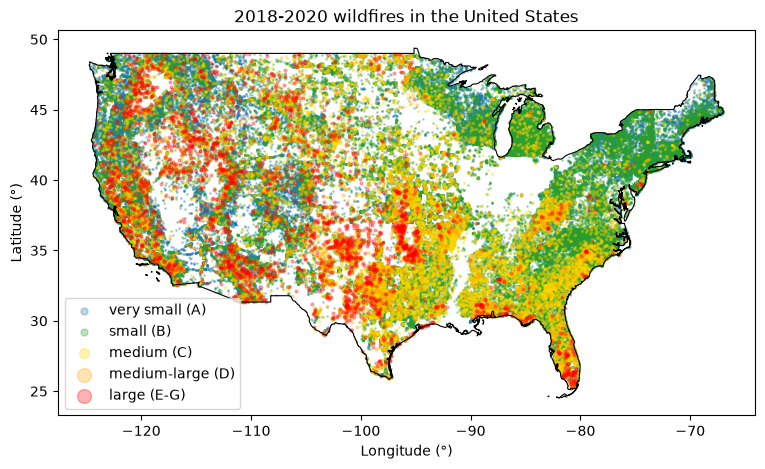

In [6]:
contour = pd.read_csv("contour_us.csv")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df.loc[y == 0, "LONGITUDE"], df.loc[y == 0, "LATITUDE"], s=1, c="tab:blue", label="very small (A)", alpha=0.3)
ax.scatter(df.loc[y == 1, "LONGITUDE"], df.loc[y == 1, "LATITUDE"], s=1, c="tab:green", label="small (B)", alpha=0.3)
ax.scatter(df.loc[y == 2, "LONGITUDE"], df.loc[y == 2, "LATITUDE"], s=2, c="gold", label="medium (C)", alpha=0.3)
ax.scatter(df.loc[y == 3, "LONGITUDE"], df.loc[y == 3, "LATITUDE"], s=4, c="orange", label="medium-large (D)", alpha=0.3)
ax.scatter(df.loc[y == 4, "LONGITUDE"], df.loc[y == 4, "LATITUDE"], s=4, c="red", label="large (E-G)", alpha=0.3)
ax.plot(contour["lon"], contour["lat"], c="black", lw=0.8)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title("2018-2020 wildfires in the United States")
ax.legend(markerscale=5)
plt.show()

The figure above shows that the spatial distribution depends on the class (47% of all fires are west of longitude -100°):

* **very small (A)**: more often in the West (63%)
* **small (B) and medium (C)**: mostly in the East (30% and 31% in the West)
* **medium-large (D)**: on both sides (51% in the West)
* **large (E-G)**: mostly in the West (71%), with clusters in the Southern Great Plains and Florida

Location is therefore informative, but a model may learn these regional differences rather than the causes of fire spread.

### Figure 2: seasonality

The figure below shows the number of fires per month (left) and the share of medium-large and large fires per month (right).

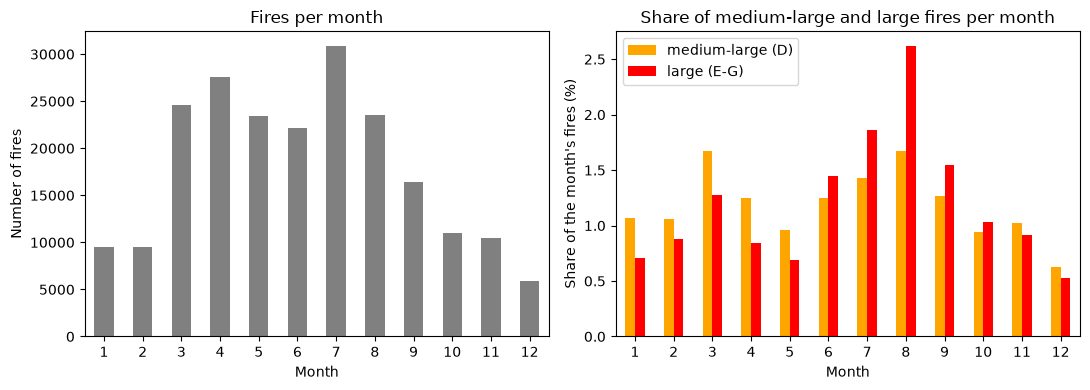

In [7]:
month = pd.to_datetime(df["DISCOVERY_DATE"]).dt.month

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
month.value_counts().sort_index().plot.bar(ax=axes[0], color="gray", rot=0)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of fires")
axes[0].set_title("Fires per month")
share = pd.crosstab(month, y, normalize="index")[[3, 4]] * 100
share.columns = ["medium-large (D)", "large (E-G)"]
share.plot.bar(ax=axes[1], color=["orange", "red"], rot=0)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Share of the month's fires (%)")
axes[1].set_title("Share of medium-large and large fires per month")
plt.tight_layout()
plt.show()

The figure above shows that fires are numerous from March to August, but that large fires are proportionally more frequent in summer.
The share of medium-large fires varies less. This seasonality justifies using the day of year as a variable (`DOY_SIN`, `DOY_COS`) and testing on a full year (section 6).

### Figure 3: selected variables by class

The figure below compares the distribution of four variables across the five size classes. Outliers are not shown.

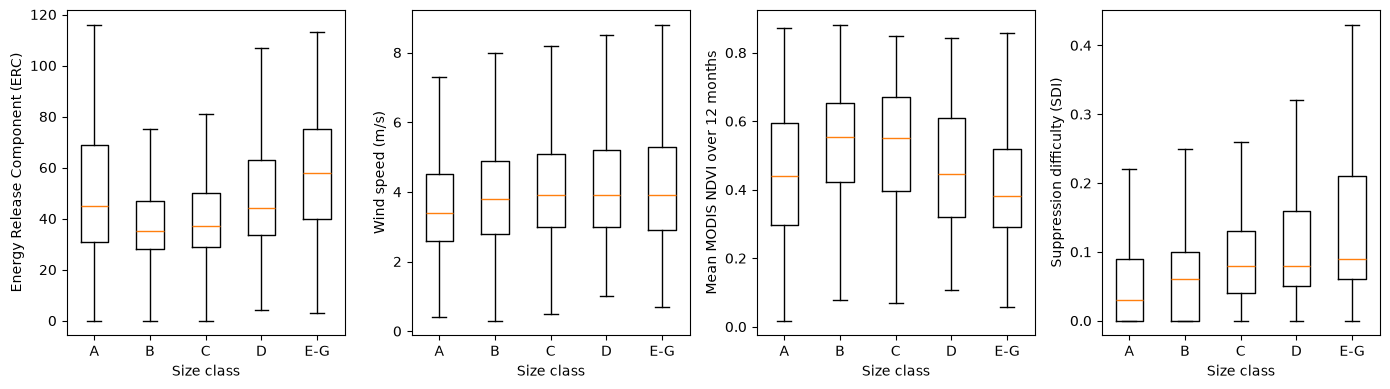

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col, label in zip(axes,
                          ["erc", "vs", "MOD_NDVI_12m_mean", "SDI"],
                          ["Energy Release Component (ERC)", "Wind speed (m/s)", "Mean MODIS NDVI over 12 months", "Suppression difficulty (SDI)"]):
    ax.boxplot([X.loc[y == k, col].dropna() for k in range(5)], showfliers=False)
    ax.set_xticks(range(1, 6), ["A", "B", "C", "D", "E-G"])
    ax.set_xlabel("Size class")
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

The figure above shows that large fires (E-G) tend to occur in dry conditions (ERC) and in less green vegetation (NDVI).
Suppression difficulty increases with the class, and wind speed slightly. 
Very small fires (A) do not follow the trend for ERC, their median is higher than for classes B and C. A likely reason is geography: A fires are more often in the West (Figure 1), which is more arid. 
The distributions overlap widely, no single variable separates the classes, which justifies a model that combines them.

### Figure 4: correlations between variables

The figure below shows the correlation between the numerical variables.

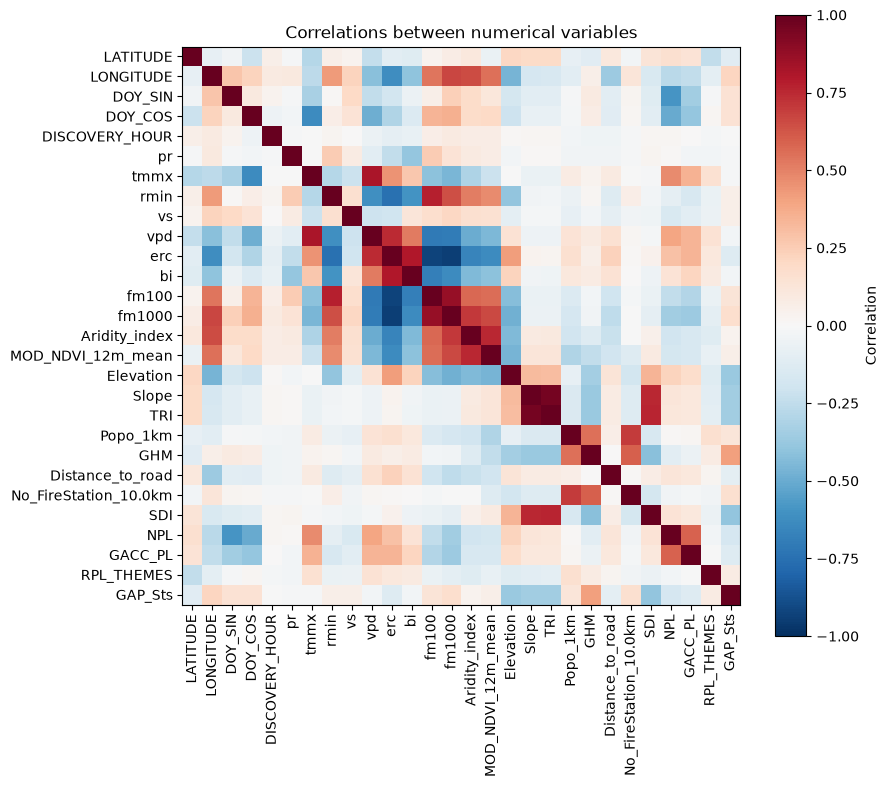

In [9]:
corr = X[NUM_FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_FEATURES)), NUM_FEATURES, rotation=90)
ax.set_yticks(range(len(NUM_FEATURES)), NUM_FEATURES)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlations between numerical variables")
plt.tight_layout()
plt.show()

The figure above shows groups of highly correlated variables:

- slope and terrain ruggedness
- ERC and fuel moisture
- maximum temperature and vapour pressure deficit
- national preparedness level and season
- aridity and NDVI
- population density and number of fire stations
- suppression difficulty and terrain
- national and regional preparedness levels

These redundancies can make a linear model unstable, so we may use regularisation or keep one variable per group. Decision trees are less sensitive to this.

## 5. Preprocessing

* **Missing values:** replaced by the median of each variable, which is not affected by extreme values (mainly `DISCOVERY_HOUR`, 21% missing, and `Distance_to_road`, 31%). The impact of this choice is tested in section 8.
* **Outliers:** kept, because extreme values (heavy rain, dense cities) are real observations.
* **Categorical variables:** `Land_Cover_1km_main` and `FRG_1km_main` are codes, not quantities, so they are one-hot encoded (one 0/1 column per class).
* **Scaling:** numerical variables are standardised (mean 0, standard deviation 1), because their scales are very different (see the table in section 4).
* **Class imbalance:** rare classes get a higher weight during training (`class_weight="balanced"`), otherwise the models would mostly predict the two majority classes. We do not subsample: one fit takes less than 10 seconds for our models, so the full training set can be used.

These steps are put in a scikit-learn pipeline with the model, so they are always fitted on the training data only.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def pipeline(model, num_features=NUM_FEATURES):
    """Returns an unfitted pipeline "preprocessing + model".

    Numerical variables (num_features): median imputation, then standardisation.
    Categorical variables (CAT_FEATURES): one-hot encoding (an unknown category gives only zeros).
    Medians, means, standard deviations and categories are learnt during .fit(), on the training data only.
    """
    prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)])
    return make_pipeline(prep, model)

## 6. Evaluation protocol

**Split by year.** A random split would put fires from the same day and place (same drought, same storm) in two sets and inflate the scores. We use one year per set:

* **train: 2018**, the models learn on these fires,
* **validation: 2019**, a full year the models have not seen, used to choose the hyperparameters,
* **test: 2020**, used only once, at the end, to compare the final models.

This reproduces the real use case (predicting the fires of a new year from past years), and no weather event is shared between two sets, except during the night of 31 December. Once the hyperparameters are chosen, the final models are retrained on 2018 and 2019 before the test.

**Metrics (3).** With a class imbalance this strong, the metrics must say how each class is recognised, not only the majority ones:

* **Accuracy:** share of correctly classified fires. It is dominated by the small fires (A and B are 89% of the data) and is used to compare with the baseline.
* **Balanced accuracy:** mean over the 5 classes of the recall (share of the fires of a class that are found). Every class counts the same, but false alarms are ignored.
* **Macro F1:** mean over the 5 classes of the F1 score, which combines recall (missed fires) and precision (false alarms). It is our main metric to choose the hyperparameters.

The confusion matrix gives the detail per class (recall on the diagonal).

The table below gives the number of fires per class in each set.

In [11]:
year = pd.to_datetime(df["DISCOVERY_DATE"]).dt.year
train, val, test = year == 2018, year == 2019, year == 2020

# 2018 and 2019 in one table, with a single predefined split for the hyperparameter search: fit on 2018, score on 2019
X_trval, y_trval = X[train | val], y[train | val]
is_val = (year[train | val] == 2019).to_numpy()
split = [(np.where(~is_val)[0], np.where(is_val)[0])]

pd.crosstab(year, y).rename(index={2018: "train (2018)", 2019: "validation (2019)", 2020: "test (2020)"}, columns=dict(enumerate(CLASSES)))

size_class,very small (A),small (B),medium (C),medium-large (D),large (E-G)
DISCOVERY_DATE,,,,,
train (2018),40144,31269,6825,1070,1155
validation (2019),30388,25321,4693,717,664
test (2020),34716,30327,5797,964,1048


The table above shows that the three years have similar class proportions: 80,463 fires in 2018, 61,783 in 2019 and 72,852 in 2020, with 1.4%, 1.1% and 1.4% of large fires.

## 7. Algorithms and hyperparameters

* **Baseline:** `DummyClassifier(strategy="most_frequent")` always predicts the most frequent class (A). Any useful model must beat it.
* **Logistic regression:** a linear model that computes one score per class as a weighted sum of the variables, turned into probabilities, and the predicted class is the most probable one. Main hyperparameter: `C`, the inverse of the regularisation strength (small `C` = coefficients kept small, less overfitting).
* **Random forest:** a vote between many decision trees, each trained on a bootstrap sample of the fires and looking at a random subset of the variables at each split, which makes the trees different and their vote more stable than one tree. Main hyperparameters: `max_depth` (maximum number of successive splits) and `min_samples_leaf` (minimum number of fires in a leaf), which control how much a tree can learn the training fires by heart. `n_estimators` is fixed to 200 (more trees only stabilise the vote) and `max_features` is left to its default (square root of the number of variables).

Both models use `class_weight="balanced"`.


## 8. Hyperparameter tuning

**Tuning strategy.** `GridSearchCV` with the predefined split tries every combination of the grids below: fit on 2018, score on 2019. With a single validation year, differences smaller than 0.01 in macro F1 are not meaningful. Our rule is therefore: keep the combinations whose validation macro F1 is within 0.01 of the best one, and among them choose the one with the smallest gap between train and validation (the least overfitting).

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import get_scorer
from sklearn.model_selection import GridSearchCV

models = {
    "dummy": (DummyClassifier(strategy="most_frequent"), {}),
    "logistic regression": (LogisticRegression(class_weight="balanced", max_iter=2000),
                            {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "random forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42),
                      {"randomforestclassifier__max_depth": [10, 20, None],
                       "randomforestclassifier__min_samples_leaf": [1, 5, 20, 50, 100]}),
}
scoring = {"macro F1": "f1_macro", "balanced accuracy": "balanced_accuracy", "accuracy": "accuracy"}


def tune(y_trval, scoring):
    """Grid search of every model on the predefined split (fit on 2018, score on 2019).

    Selection rule on the first metric of `scoring`: among the combinations within 0.01 of the best
    validation score, keep the one with the smallest gap between train and validation.
    """
    main = next(iter(scoring))
    rows = []
    for name, (model, grid) in models.items():
        res = GridSearchCV(pipeline(model), grid, cv=split, scoring=scoring, refit=False, return_train_score=True).fit(X_trval, y_trval).cv_results_
        for i, params in enumerate(res["params"]):
            rows.append({"model": name, "hyperparameters": {k.split("__")[1]: v for k, v in params.items()},
                         **{f"val {m}": res[f"mean_test_{m}"][i] for m in scoring},
                         f"train {main}": res[f"mean_train_{main}"][i]})
    results = pd.DataFrame(rows)
    results["gap"] = results[f"train {main}"] - results[f"val {main}"]
    near_best = results[f"val {main}"] >= results.groupby("model")[f"val {main}"].transform("max") - 0.01
    chosen = results[near_best].sort_values("gap").groupby("model").head(1).set_index("model")
    return results, chosen


results, chosen = tune(y_trval, scoring)
results.round(3)

,model,hyperparameters,val macro F1,val balanced accuracy,val accuracy,train macro F1,gap
0,dummy,{},0.132,0.200,0.492,0.133,0.001
1,logistic regression,{'C': 0.01},0.315,0.410,0.504,0.321,0.006
2,logistic regression,{'C': 0.1},0.316,0.411,0.505,0.322,0.006
3,logistic regression,{'C': 1},0.316,0.411,0.505,0.322,0.006
4,logistic regression,{'C': 10},0.315,0.410,0.505,0.322,0.007
5,random forest,"{'max_depth': 10, 'min_samples_leaf': 1}",0.350,0.442,0.553,0.466,0.116
6,random forest,"{'max_depth': 10, 'min_samples_leaf': 5}",0.349,0.447,0.550,0.458,0.108
7,random forest,"{'max_depth': 10, 'min_samples_leaf': 20}",0.347,0.451,0.546,0.435,0.087
8,random forest,"{'max_depth': 10, 'min_samples_leaf': 50}",0.342,0.454,0.539,0.408,0.065
9,random forest,"{'max_depth': 10, 'min_samples_leaf': 100}",0.338,0.454,0.530,0.386,0.048


The table above gives the validation (2019) and train (2018) scores of every combination:

* **Dummy:** macro F1 of 0.132 and balanced accuracy of 0.2 (it only recognises class A), but already 49% accuracy, which shows why accuracy alone is misleading here.
* **Logistic regression:** `C` has almost no effect (validation macro F1 between 0.315 and 0.316), and train and validation scores are almost equal (gap below 0.01): the model does not overfit, it is rather too simple for the data (underfitting). The rule keeps `C=0.1`.
* **Random forest:** the best validation macro F1 (0.380) is obtained with `max_depth=None` and `min_samples_leaf=5`, but with a train macro F1 of 0.90 (strong overfitting). `max_depth=20` and `min_samples_leaf=20` reach 0.379, within 0.01, with a gap of 0.23 instead of 0.52 and a better balanced accuracy (0.444 against 0.374): the rule keeps this combination. With `max_depth=10`, the trees are too short (validation macro F1 of 0.350 at most).

The figure below shows, for the random forest, the train (dashed) and validation (solid) macro F1 as a function of `min_samples_leaf`, for each value of `max_depth`.

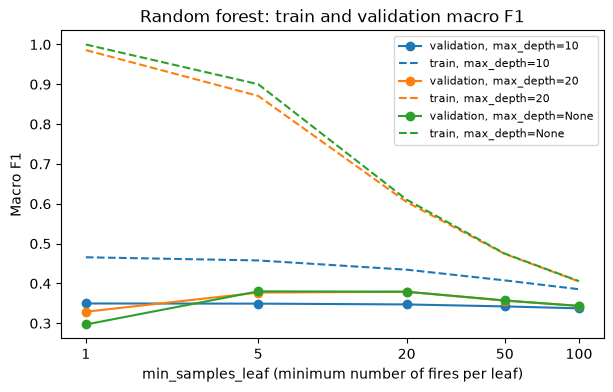

In [13]:
rf = results[results["model"] == "random forest"].copy()
rf["max_depth"] = rf["hyperparameters"].map(lambda p: str(p["max_depth"]))
rf["min_samples_leaf"] = rf["hyperparameters"].map(lambda p: p["min_samples_leaf"])

fig, ax = plt.subplots(figsize=(7, 4))
for (depth, g), color in zip(rf.groupby("max_depth", sort=False), ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(g["min_samples_leaf"], g["val macro F1"], marker="o", color=color, label=f"validation, max_depth={depth}")
    ax.plot(g["min_samples_leaf"], g["train macro F1"], ls="--", color=color, label=f"train, max_depth={depth}")
ax.set_xscale("log")
ax.set_xticks([1, 5, 20, 50, 100], [1, 5, 20, 50, 100])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel("min_samples_leaf (minimum number of fires per leaf)")
ax.set_ylabel("Macro F1")
ax.set_title("Random forest: train and validation macro F1")
ax.legend(fontsize=8)
plt.show()

The figure above shows the usual overfitting pattern. The train macro F1 (dashed) decreases when `min_samples_leaf` increases, from almost 1 with one fire per leaf (the trees learn the training fires by heart) to about 0.4 with 100. The validation macro F1 (solid) is lower with one fire per leaf, reaches its maximum between 5 and 20, then decreases when the trees become too simple. `max_depth=20` and `max_depth=None` give almost the same curves, so the depth only matters when it is too small (`max_depth=10`, flat and lower).

**Impact of the imputation.** `DISCOVERY_HOUR` and `Distance_to_road` have many missing values, replaced by the median. The table below compares the validation scores of the chosen random forest with and without these two variables.

In [14]:
best_rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42, **chosen.loc["random forest", "hyperparameters"])
without = [f for f in NUM_FEATURES if f not in ("DISCOVERY_HOUR", "Distance_to_road")]
pd.DataFrame({name: {m: get_scorer(s)(pipeline(best_rf, feats).fit(X[train], y[train]), X[val], y[val]) for m, s in scoring.items()}
              for name, feats in [("with", NUM_FEATURES), ("without", without)]}).T.round(3)

,macro F1,balanced accuracy,accuracy
with,0.379,0.444,0.604
without,0.376,0.440,0.603


The table above shows that removing the two imputed variables changes the scores by less than 0.01 (macro F1 of 0.379 with, 0.376 without). The median imputation does not harm the model, but these two variables bring almost no information. We keep them. Other imputation strategies (for example a column indicating the missing values) were not tested.

## 9. Results on the test set (2020)

Each model is retrained with its chosen hyperparameters on 2018 and 2019, then evaluated once on 2020. The train macro F1 (on 2018-2019) is given to check overfitting.

In [15]:
from sklearn.base import clone


def evaluate(chosen, y_trval, y_test, scoring):
    """Retrains each model with its chosen hyperparameters on 2018-2019, then scores it once on the test year 2020."""
    main = next(iter(scoring))
    final, scores = {}, {}
    for name, (model, _) in models.items():
        params = chosen.loc[name, "hyperparameters"]
        final[name] = pipeline(clone(model).set_params(**params)).fit(X_trval, y_trval)
        scores[name] = {"hyperparameters": params,
                        **{f"test {m}": round(get_scorer(s)(final[name], X[test], y_test), 3) for m, s in scoring.items()},
                        f"train {main}": round(get_scorer(scoring[main])(final[name], X_trval, y_trval), 3)}
    return final, pd.DataFrame(scores).T


final, test_scores = evaluate(chosen, y_trval, y[test], scoring)
test_scores

,hyperparameters,test macro F1,test balanced accuracy,test accuracy,train macro F1
dummy,{},0.129,0.2,0.477,0.133
logistic regression,{'C': 0.1},0.285,0.406,0.429,0.313
random forest,"{'max_depth': 20, 'min_samples_leaf': 20}",0.343,0.424,0.534,0.599


The table above shows that the random forest is the best model on the test set for the three metrics (macro F1 of 0.343, balanced accuracy of 0.424, accuracy of 0.534), and that both models clearly beat the dummy baseline in macro F1 and balanced accuracy. The logistic regression has a lower accuracy than the dummy (0.429 against 0.477): it often predicts rare classes for fires that are actually small (see below). The scores are lower than on the validation year (macro F1 of 0.379 for the random forest and 0.316 for the logistic regression), which is discussed in section 12. The random forest still overfits (train macro F1 of 0.60 against 0.34 on the test set).

The figure below shows the confusion matrices of the two models on the test set. Rows are normalised: the diagonal is the recall of each class.

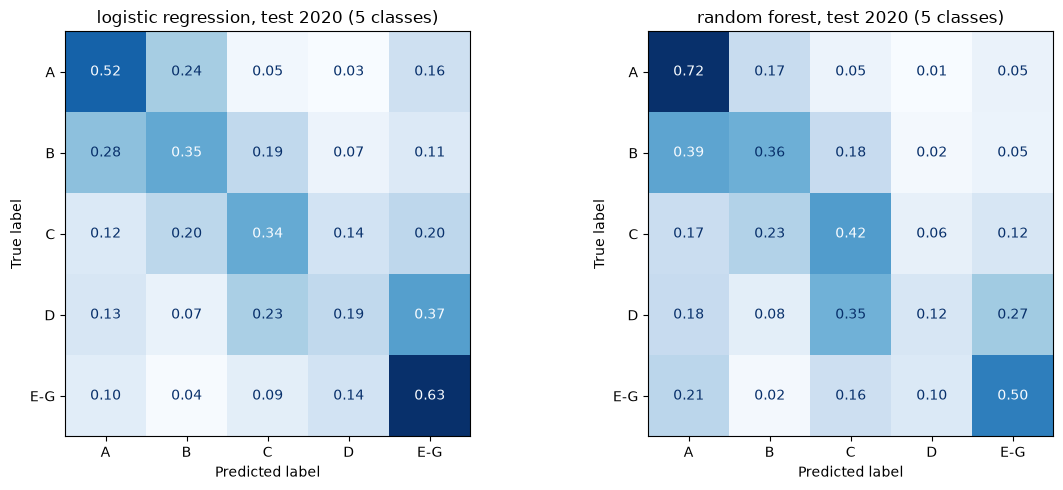

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay


def plot_confusion(final, y_test, labels, task):
    """Row-normalised confusion matrices of the two models on the test year (the diagonal is the recall of each class)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, name in zip(axes, ["logistic regression", "random forest"]):
        ConfusionMatrixDisplay.from_estimator(final[name], X[test], y_test, normalize="true", display_labels=labels,
                                              values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"{name}, test 2020 ({task})")
    plt.tight_layout()
    plt.show()


plot_confusion(final, y[test], ["A", "B", "C", "D", "E-G"], "5 classes")

The figure above shows that the two models make different compromises:

* **Logistic regression** finds the most large fires (63%), but at the cost of many false alarms: 16% of the very small fires and 11% of the small ones are predicted as large. Small and medium fires are poorly recognised (35% to 52%).
* **Random forest** finds fewer large fires (50%) but gives fewer false alarms (5% of the very small fires predicted as large) and recognises the very small fires better (72%).

Both models often underestimate the size: 35% of the medium-large fires (D) are predicted as medium (C) by the random forest, and 21% of the large fires are predicted as very small (A). Class D is the hardest (12% to 19% recall): it lies between C and E-G and is rare. In 2020, small fires (B) are often confused with very small ones (39% for the random forest).

## 10. Reformulation as a binary task: large fire or not

**Why.** The 5-class results above show three things:

* the scores are limited (test macro F1 of 0.343 for the random forest), and a large part of the errors are confusions between neighbouring classes (A and B, B and C, C and D), which weigh a lot in the macro F1 but matter little for firefighting,
* class D (100 to 299 acres) is almost never recognised (12% to 19% recall): it lies between C and E-G and is rare,
* tuning, the choice of the algorithm and the imputation test do not change this level. Exploratory tests that are not included in this notebook (a gradient boosting model, ERC relative to its local normal, and the reporting agency, the cause and the cheatgrass cover as new variables) did not either: the limit comes from the information available at discovery, not from the model.

At discovery, the decision that matters most for emergency management is whether the fire may become large, to send resources early. We therefore also study the simpler question: **will the fire reach 300 acres or more (class E-G)?** The protocol, the models, the grids and the selection rule are the same, only the target and the metrics change.

**Metrics.** Large fires are only 1.3% of the data, so the accuracy of a model that never predicts "large" is about 99%. We use the **F1 score of the large class** (main metric, it combines the recall of the large fires and the precision of the alerts), the **balanced accuracy** (mean of the recall of the two classes), and the **accuracy** for comparison with the dummy.

In [17]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  # the dummy never predicts "large": its F1 is 0 by convention

y_large = (y == 4).astype(int).rename("large")  # 1 = large fire (class E-G, 300 acres or more)
scoring_bin = {"F1 (large fires)": "f1", "balanced accuracy": "balanced_accuracy", "accuracy": "accuracy"}
results_bin, chosen_bin = tune(y_large[train | val], scoring_bin)
results_bin.round(3)

,model,hyperparameters,val F1 (large fires),val balanced accuracy,val accuracy,train F1 (large fires),gap
0,dummy,{},0.000,0.500,0.989,0.000,0.000
1,logistic regression,{'C': 0.01},0.090,0.802,0.834,0.104,0.013
2,logistic regression,{'C': 0.1},0.092,0.804,0.836,0.104,0.012
3,logistic regression,{'C': 1},0.092,0.803,0.836,0.104,0.012
4,logistic regression,{'C': 10},0.092,0.803,0.836,0.104,0.012
5,random forest,"{'max_depth': 10, 'min_samples_leaf': 1}",0.131,0.770,0.911,0.235,0.104
6,random forest,"{'max_depth': 10, 'min_samples_leaf': 5}",0.128,0.765,0.910,0.230,0.102
7,random forest,"{'max_depth': 10, 'min_samples_leaf': 20}",0.129,0.783,0.905,0.218,0.088
8,random forest,"{'max_depth': 10, 'min_samples_leaf': 50}",0.122,0.792,0.893,0.196,0.075
9,random forest,"{'max_depth': 10, 'min_samples_leaf': 100}",0.112,0.802,0.876,0.171,0.059


The table above gives the validation (2019) and train (2018) scores of every combination for the binary task:

* **Dummy:** F1 of 0 (it never predicts "large") but an accuracy of 0.989, which confirms that accuracy is useless for this task.
* **Logistic regression:** `C` has again almost no effect (F1 between 0.090 and 0.092) and there is no overfitting (gap of about 0.01). Its balanced accuracy is high (0.80) but its F1 is low: it finds most large fires, with many false alarms.
* **Random forest:** the best F1 (0.197) is obtained with `max_depth=None` and `min_samples_leaf=20`, and `max_depth=20` and `min_samples_leaf=20` reach 0.192, within 0.01, with a smaller gap (0.33 against 0.37), and are kept by our rule. With very deep trees and small leaves, the forest overfits completely (train F1 of 1.0) and almost never predicts "large" (validation F1 of 0 and 0.035). Larger leaves increase the balanced accuracy (up to 0.80) but decrease the F1: the same trade-off between found large fires and false alarms as in the 5-class task.

The table below gives the test scores of the binary models, retrained on 2018-2019 with their chosen hyperparameters.

In [18]:
final_bin, test_scores_bin = evaluate(chosen_bin, y_large[train | val], y_large[test], scoring_bin)
test_scores_bin

,hyperparameters,test F1 (large fires),test balanced accuracy,test accuracy,train F1 (large fires)
dummy,{},0.0,0.5,0.986,0.0
logistic regression,{'C': 0.1},0.09,0.795,0.759,0.094
random forest,"{'max_depth': 20, 'min_samples_leaf': 20}",0.201,0.649,0.963,0.498


The table above shows that the random forest has the best F1 on the test set (0.201 against 0.090 for the logistic regression), while the logistic regression has the best balanced accuracy (0.795 against 0.649). The two models make opposite compromises, detailed by the confusion matrices below. The test F1 of the random forest is close to its validation F1 (0.192): unlike the 5-class task (0.379 on validation, 0.343 on test), the binary task generalises well from 2019 to 2020. The random forest still overfits (train F1 of 0.50).

The figure below shows the confusion matrices of the binary models on the test set. Rows are normalised: the diagonal is the recall of each class.

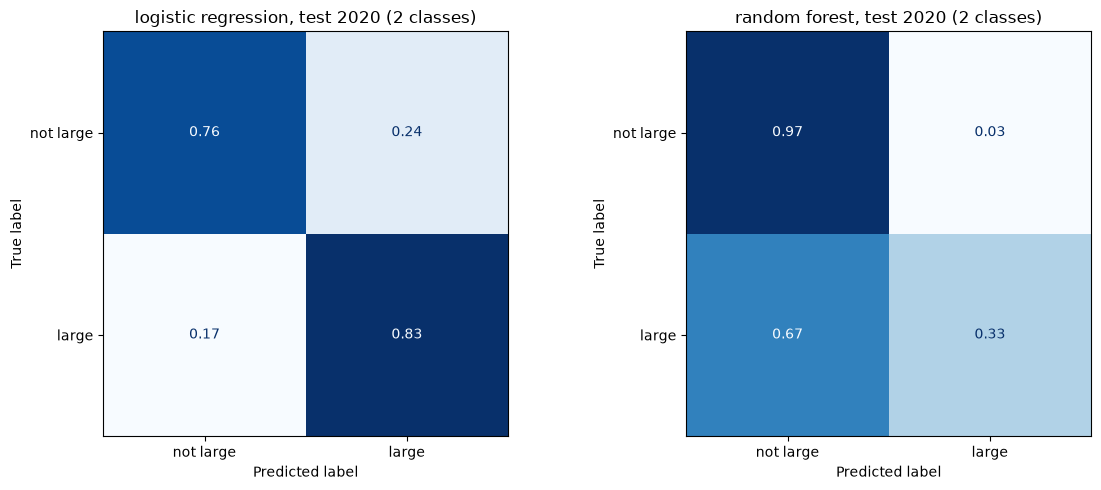

In [19]:
plot_confusion(final_bin, y_large[test], ["not large", "large"], "2 classes")

The figure above shows the two compromises:

* **Logistic regression** finds 83% of the large fires, but 24% of the other fires are also predicted as large: about 18,000 alerts for 1,048 large fires, so only about 5% of the alerts are right.
* **Random forest** finds only 33% of the large fires, but with 3% of false alarms: about 2,500 alerts, of which about 14% are right.

Compared with the 5-class random forest (50% of the large fires found, 5% of the very small fires predicted as large), the binary random forest is more cautious: slightly better precision, but fewer large fires found. **The reformulation removes the confusions between neighbouring classes, but it does not make the large fires easier to detect**: whatever the formulation, the variables known at discovery only partly separate the fires that will become large. An operational use would require choosing a decision threshold on the predicted probability, according to the number of alerts the firefighting services can handle (not done here).

## 11. Advantages and disadvantages of the two algorithms

| | Logistic regression | Random forest |
|---|---|---|
| **Theoretical advantages** | Simple, fast, interpretable coefficients, little risk of overfitting with regularisation | Captures non-linear effects and interactions between variables (e.g. the same ERC means different things in the West and in the East), insensitive to scaling and to correlated variables |
| **Theoretical disadvantages** | Linear decision boundaries, sensitive to scaling and to correlated variables (Figure 4) | Many hyperparameters, can learn the training data by heart, harder to interpret |
| **Empirical advantages (our results)** | No overfitting (train and validation scores within 0.01), best recall of the large fires on the test set (63%), one fit in a few seconds | Best scores on the three metrics, on validation and test (test macro F1 of 0.343), fewer false alarms |
| **Empirical disadvantages (our results)** | Lowest scores (test macro F1 of 0.285), accuracy below the dummy (0.429 against 0.477) because of the many false alarms, `C` has no effect, a sign of underfitting | Strong overfitting without tuning (train macro F1 of 1.0), still a gap after tuning (0.60 train, 0.34 test), finds fewer large fires than the logistic regression (50%) |

## 12. Critical analysis

* **Limited predictability.** The random forest is better than the baseline (test macro F1 of 0.343 against 0.129), but far from perfect. The final size of a fire also depends on what happens after its discovery (weather of the following days, firefighting decisions), which no variable of the dataset describes.
* **Drop between validation and test.** The macro F1 goes from 0.379 to 0.343 for the random forest and from 0.316 to 0.285 for the logistic regression. Each year has its own conditions (2020 was, for example, an exceptional fire season in the western United States), so a model trained on past years generalises imperfectly to a new one. With a single validation year, we also have one score per combination and no measure of its variability.
* **Reformulation.** Predicting only "large fire or not" (section 10) gives more stable scores between validation and test, but the large fires are not better detected: this confirms that the limit comes from the data available at discovery rather than from the number of classes.
* **Missed large fires or false alarms.** Improving the recall of the large fires increases the false alarms, as the comparison of the two models shows. The right compromise depends on the cost of each error for firefighting services, which we did not quantify. Macro F1 gives the same weight to both errors.
* **Location.** The size classes have very different spatial distributions (Figure 1), so location is informative. The model may learn regional differences in reporting and firefighting rather than the physics of fire spread, so it should not be applied to another region (e.g. Europe) without a spatial validation.
* **Ordered classes.** The metrics treat all errors equally, although predicting a large fire as very small (A instead of E-G) is much worse than predicting it as medium-large (D).
* **Data.** The weather variables are daily values of the discovery day, so they include a few hours after the discovery (a slight leak). `DISCOVERY_HOUR` and `Distance_to_road` are often missing, and the class boundaries (0.26, 10, 100, 300 acres) are conventions.
* **Tuning.** The grids are small and `max_features` was not tuned. The 0.01 threshold of our selection rule is a choice, not a measured uncertainty.

## Use of AI
